# Control supervisorio con DESlab: dos máquinas y un buffer

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/DESlab_Colab_supervisorio.ipynb)

Problema clásico de control supervisorio (Ramadge y Wonham): dos máquinas en serie conectadas
por un buffer de capacidad 1.

```
  piezas ──► M1 ──► [ buffer ] ──► M2 ──►
```

La máquina $M_1$ toma una pieza, la procesa y la deja en el buffer; la máquina $M_2$ toma la pieza
del buffer y la procesa. Se busca un supervisor que evite que el buffer se desborde ($M_1$ deja una
pieza con el buffer lleno) y que $M_2$ arranque con el buffer vacío, restringiendo lo menos posible
el funcionamiento de las máquinas y sin bloquear el sistema.

Pasos:

1. Modelar la planta $G = M_1 \parallel M_2$ e indicar qué eventos son controlables.
2. Modelar la especificación $E$ y construir $H = G \parallel E$, que marca el lenguaje deseado $K = L_m(H)$.
3. Verificar si $K$ es controlable.
4. Calcular el supremo sublenguaje controlable $K^{\uparrow C}$ con `supcontrollable`: el autómata
   que lo marca es el supervisor $S$, el menos restrictivo y no bloqueante.

Al final se resuelve la versión con averías y prioridad de reparación (la *small factory* de Wonham).

In [1]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import shutil, subprocess

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q git+https://github.com/nebisman/deslab-py3.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from deslab import *

## 1. Planta: las dos máquinas

Cada máquina $M_i$ tiene dos estados, $I_i$ (en reposo) y $W_i$ (trabajando), y dos eventos:

| Evento | Significado | Tipo |
|---|---|---|
| $\alpha_i$ | la máquina toma una pieza y empieza a trabajar | controlable |
| $\beta_i$ | la máquina termina y entrega la pieza | no controlable |

$M_1$ deja la pieza en el buffer con $\beta_1$ y $M_2$ la toma del buffer con $\alpha_2$.
El estado de reposo es el marcado (tarea terminada).

**Eventos controlables en DESlab.** Se indican con el parámetro `Sigcon`. Si se omite, DESlab
considera *todos* los eventos controlables, y la composición paralela une los conjuntos `Sigcon`
de los componentes; por eso hay que darlo en cada máquina.

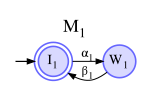

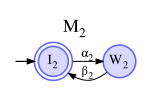

In [3]:
syms('I1 W1 I2 W2 a1 b1 a2 b2')
table = [(a1, '\\alpha_1'), (b1, '\\beta_1'), (a2, '\\alpha_2'), (b2, '\\beta_2'),
         (I1, 'I_1'), (W1, 'W_1'), (I2, 'I_2'), (W2, 'W_2')]

M1 = fsa([I1, W1], [a1, b1], [(I1, a1, W1), (W1, b1, I1)], [I1], [I1], table,
         Sigcon=[a1], name='$M_1$')
M2 = fsa([I2, W2], [a2, b2], [(I2, a2, W2), (W2, b2, I2)], [I2], [I2], table,
         Sigcon=[a2], name='$M_2$')
draw(M1, M2)

Eventos:         ['a1', 'a2', 'b1', 'b2']
Controlables:    ['a1', 'a2']
No controlables: ['b1', 'b2']


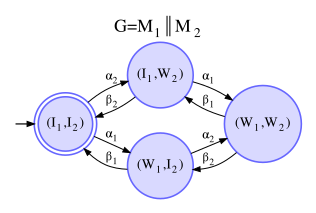

In [4]:
G = (M1 // M2).setpar(name='$G = M_1 \\parallel M_2$')
print('Eventos:        ', sorted(G.Sigma))
print('Controlables:   ', sorted(G.Sigcon))
print('No controlables:', sorted(G.Sigma - G.Sigcon))
draw(G)

## 2. Especificación: buffer de capacidad 1

El buffer tiene dos estados: $0$ (vacío) y $1$ (lleno). $\beta_1$ deja una pieza y $\alpha_2$ la retira.
Como $E$ no tiene $\beta_1$ en el estado $1$ ni $\alpha_2$ en el estado $0$, prohíbe el desborde y que
$M_2$ arranque sin pieza. Se marca el estado $0$: al terminar, el buffer debe quedar vacío.

$H = G \parallel E$ combina la planta con la especificación y marca el lenguaje deseado $K = L_m(H)$.
Sus estados son pares (estado de $G$, estado de $E$).

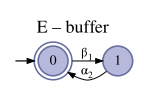

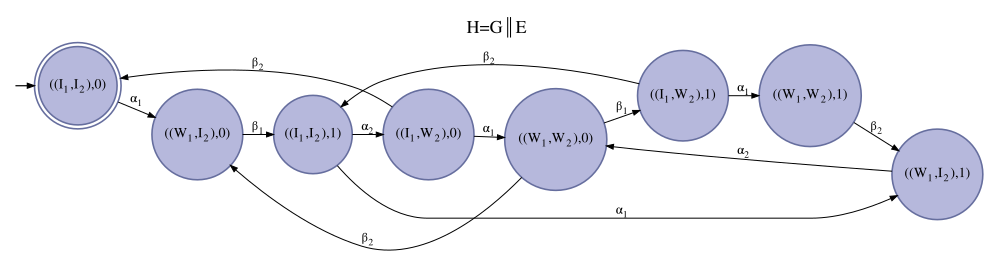

In [5]:
syms('B0 B1')
table += [(B0, '0'), (B1, '1')]

E = fsa([B0, B1], [b1, a2], [(B0, b1, B1), (B1, a2, B0)], [B0], [B0], table,
        name='$E$ -- buffer', type='specification')
H = (G // E).setpar(name='$H = G \\parallel E$', type='specification')
draw(E, H)

## 3. ¿Es controlable $K$?

$K$ es controlable con respecto a $L(G)$ y a los eventos no controlables $\Sigma_{uc}$ si
$\overline{K}\,\Sigma_{uc} \cap L(G) \subseteq \overline{K}$: la especificación nunca debe prohibir un
evento no controlable que la planta puede ejecutar, porque el supervisor no lo puede impedir.
`iscontrollable(H, G)` hace esa prueba. La celda lista además los estados de $H$ donde falla.

In [6]:
print('¿K es controlable?', iscontrollable(H, G))

Sigma_uc = G.Sigma - G.Sigcon
for (x, e) in sorted(H.X):
    prohibidos = (G.Gamma(x) & Sigma_uc) - H.Gamma((x, e))
    if prohibidos:
        print(f'en el estado {(x, e)} H prohíbe {sorted(prohibidos)}, que no es controlable')

¿K es controlable? False
en el estado (('W1', 'I2'), 'B1') H prohíbe ['b1'], que no es controlable
en el estado (('W1', 'W2'), 'B1') H prohíbe ['b1'], que no es controlable


En los dos estados la máquina 1 trabaja con el buffer lleno: cuando termine ($\beta_1$, no
controlable) el buffer se desborda, y el supervisor no lo puede evitar. Hay que actuar antes,
deshabilitando $\alpha_1$ cuando el buffer está lleno. Eso es lo que calcula el supremo sublenguaje
controlable.

## 4. Supervisor: supremo sublenguaje controlable

`supcontrollable(H, G)` devuelve un autómata que marca $K^{\uparrow C}$, el mayor sublenguaje
controlable de $K$. Como $K$ no es prefijo-cerrado se usa el algoritmo general: se construye
$H \times G$, se eliminan los estados donde algún evento no controlable posible en $G$ no está
habilitado, se recorta con `trim` y se repite hasta que no haya cambios. El autómata resultante es el
supervisor $S$: en cada estado habilita sólo los eventos que tiene definidos.

`supcontrollable` numera los estados. La función `con_estados_de` los renombra con el estado de $H$
que corresponde a cada uno, para leer el dibujo en términos de las máquinas y el buffer.

Using General Algorithm


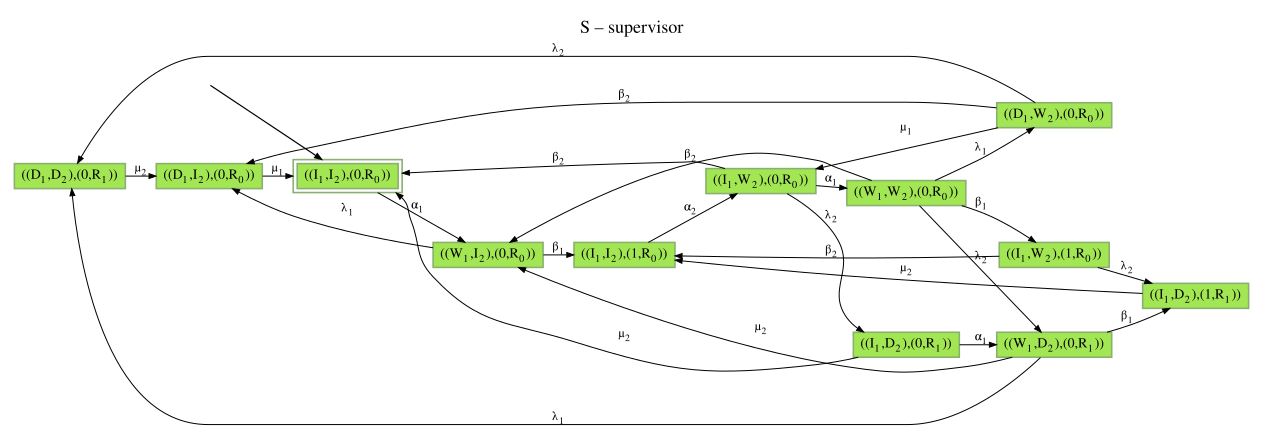

In [32]:
def con_estados_de(S, H):
    """Renombra los estados de S (calculado a partir de H) con el estado
    de H que corresponde a cada uno."""
    mapping = {s: h for (s, h) in product(S, H).X}
    return S.renamestates(mapping).setpar(table=H.symDict)

S = supcontrollable(H, G, verbose=True)
S = con_estados_de(S, H).setpar(name='$S$ -- supervisor', type='supervisor')
S.style = 'verifier'
draw(S)

In [10]:
print('¿S es controlable?         ', iscontrollable(S, G))
print('¿Lm(S) ⊆ K?                ', S <= H)
print('¿S es no bloqueante (trim)?', S == trim(S))

¿S es controlable?          True
¿Lm(S) ⊆ K?                 True
¿S es no bloqueante (trim)? True


## 5. Acción de control

En cada estado del supervisor, los eventos que la planta puede ejecutar pero que $S$ no tiene definidos
son los que el supervisor deshabilita. Todos deben ser controlables.

In [11]:
def accion_de_control(S, G):
    """Para cada estado (x, e) de S (x: estado de la planta, e: estado de la
    especificación) muestra los eventos habilitados y los que S deshabilita."""
    nombre = lambda s: ','.join(s) if isinstance(s, tuple) else str(s)
    print(f"{'planta':10}{'especif.':10}{'habilitados':24}deshabilitados")
    for (x, e) in sorted(S.X):
        habilitados = S.Gamma((x, e))
        deshabilitados = G.Gamma(x) - habilitados
        assert deshabilitados <= G.Sigcon  # S sólo deshabilita eventos controlables
        print(f'{nombre(x):10}{nombre(e):10}{", ".join(sorted(habilitados)):24}'
              f'{", ".join(sorted(deshabilitados))}')

accion_de_control(S, G)

planta    especif.  habilitados             deshabilitados
I1,I2     B0        a1                      a2
I1,I2     B1        a2                      a1
I1,W2     B0        a1, b2                  
I1,W2     B1        b2                      a1
W1,I2     B0        b1                      a2
W1,W2     B0        b1, b2                  


El supervisor deshabilita $\alpha_1$ siempre que el buffer está lleno (evita el desborde) y $\alpha_2$
cuando está vacío (evita que $M_2$ arranque sin pieza). Fuera de eso no restringe nada: es el
supervisor menos restrictivo que cumple la especificación.

## 6. Fábrica con averías y prioridad de reparación

En la versión de Wonham (*small factory*) cada máquina puede averiarse mientras trabaja; la pieza
que procesaba se descarta y la máquina queda en el estado $D_i$ (averiada) hasta que la reparan:

| Evento | Significado | Tipo |
|---|---|---|
| $\lambda_i$ | avería | no controlable |
| $\mu_i$ | reparación | controlable |

Especificaciones:

- $E_1$: el buffer de capacidad 1, igual que antes.
- $E_2$: prioridad de reparación. Si $M_2$ está averiada, $M_1$ no se puede reparar hasta que se
  repare $M_2$: $\mu_1$ sólo se permite en $R_0$.

La especificación total es $E = E_1 \parallel E_2$.

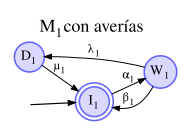

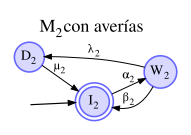

In [12]:
syms('D1 D2 l1 m1 l2 m2 R0 R1')
table += [(l1, '\\lambda_1'), (m1, '\\mu_1'), (l2, '\\lambda_2'), (m2, '\\mu_2'),
          (D1, 'D_1'), (D2, 'D_2'), (R0, 'R_0'), (R1, 'R_1')]

M1 = fsa([I1, W1, D1], [a1, b1, l1, m1],
         [(I1, a1, W1), (W1, b1, I1), (W1, l1, D1), (D1, m1, I1)],
         [I1], [I1], table, Sigcon=[a1, m1], name='$M_1$ con averías')
M2 = fsa([I2, W2, D2], [a2, b2, l2, m2],
         [(I2, a2, W2), (W2, b2, I2), (W2, l2, D2), (D2, m2, I2)],
         [I2], [I2], table, Sigcon=[a2, m2], name='$M_2$ con averías')
G = (M1 // M2).setpar(name='$G = M_1 \\parallel M_2$')
draw(M1, M2)

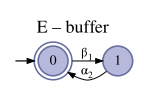

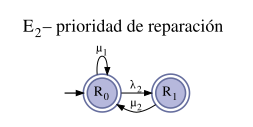

G: 9 estados;  H: 18 estados
¿K es controlable? False


In [27]:
E1 = E.setpar(name='$E_1$ -- buffer')
E1 = E.setpar(Xm= [B0])

E2 = fsa([R0, R1], [l2, m2, m1], [(R0, m1, R0), (R0, l2, R1), (R1, m2, R0)], [R0], [R0, R1],
         table, name='$E_2$ -- prioridad de reparación', type='specification')
H = G // (E1 // E2)
draw(E1, E2)
print('G:', len(G), 'estados;  H:', len(H), 'estados')
print('¿K es controlable?', iscontrollable(H, G))

Using General Algorithm
¿S es controlable?          True
¿Lm(S) ⊆ K?                 True
¿S es no bloqueante (trim)? True
S: 12 estados, 24 transiciones


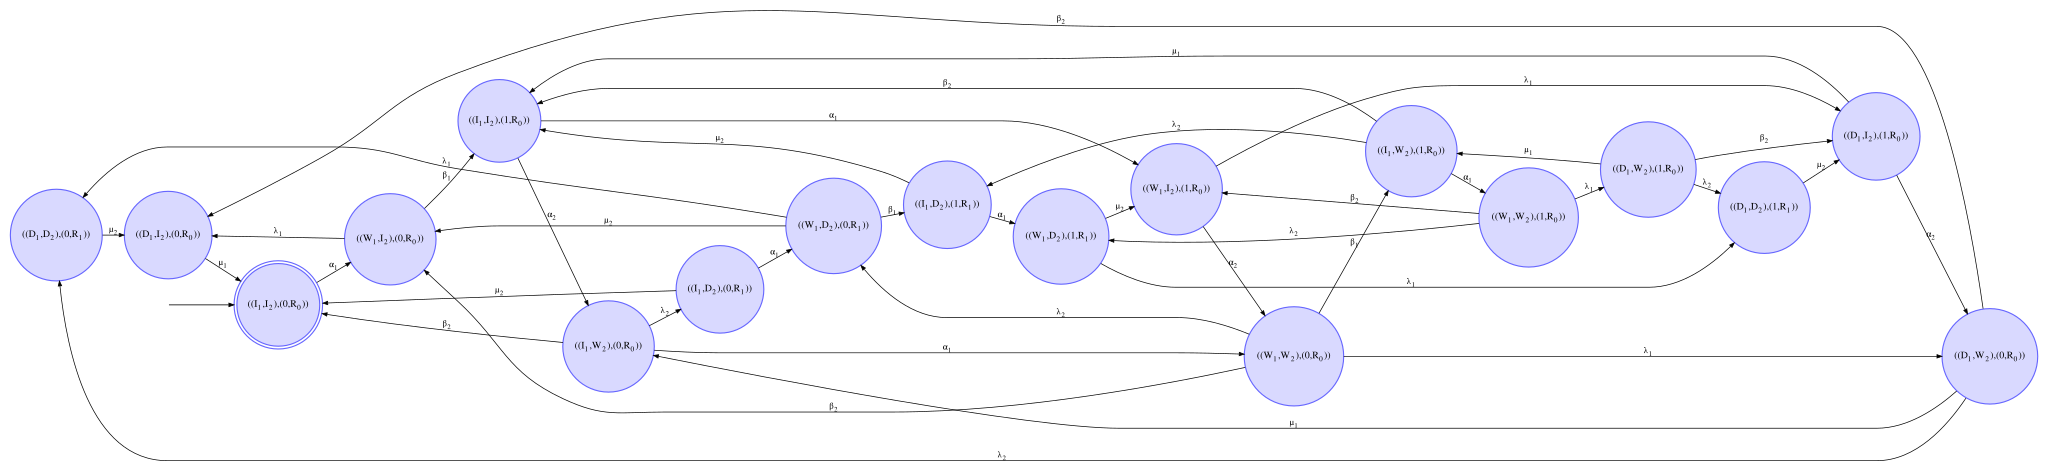

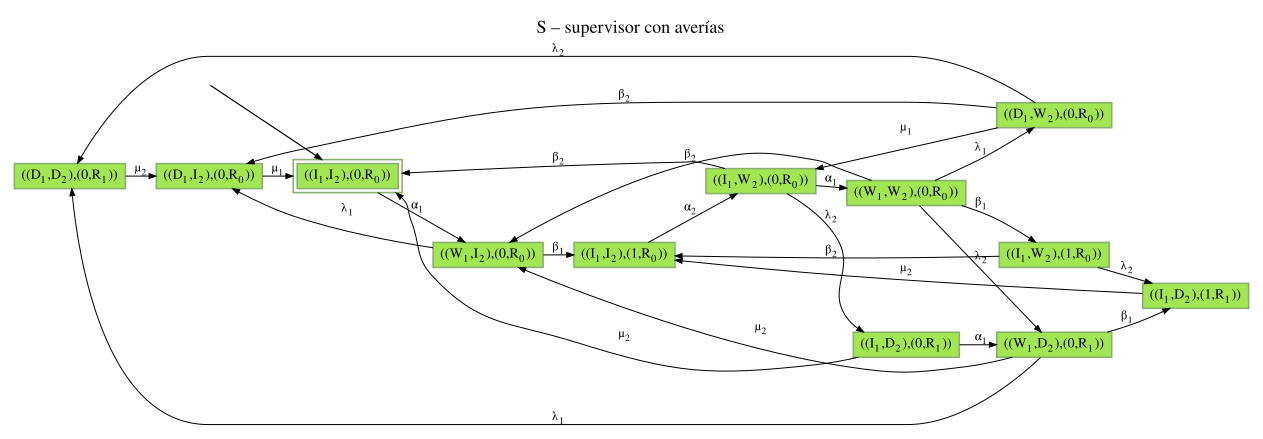

In [28]:
S = supcontrollable(H, G, verbose=True)

S = con_estados_de(S, H).setpar(name='$S$ -- supervisor con averías', type='supervisor')
S.style='diagnoser'
print('¿S es controlable?         ', iscontrollable(S, G))
print('¿Lm(S) ⊆ K?                ', S <= H)
print('¿S es no bloqueante (trim)?', S == trim(S))
print('S:', len(S), 'estados,', S.Graph.size(), 'transiciones')
draw(H,S)

In [ ]:
accion_de_control(S, G)

planta    especif.  habilitados             deshabilitados
D1,D2     B0,R1     m2                      m1
D1,I2     B0,R0     m1                      a2
D1,W2     B0,R0     b2, l2, m1              
I1,D2     B0,R1     a1, m2                  
I1,D2     B1,R1     m2                      a1
I1,I2     B0,R0     a1                      a2
I1,I2     B1,R0     a2                      a1
I1,W2     B0,R0     a1, b2, l2              
I1,W2     B1,R0     b2, l2                  a1
W1,D2     B0,R1     b1, l1, m2              
W1,I2     B0,R0     b1, l1                  a2
W1,W2     B0,R0     b1, b2, l1, l2          


Además de las restricciones del buffer, en el estado $((D_1, D_2), (0, R_1))$ el supervisor
deshabilita $\mu_1$: con las dos máquinas averiadas se repara primero $M_2$. $\alpha_1$ sigue
deshabilitada con el buffer lleno aunque $M_2$ esté averiada, porque $\beta_1$ desbordaría el buffer.

## Ejercicios

1. Cambie la capacidad del buffer a 2 (estados $0$, $1$, $2$). ¿Cuántos estados tiene el supervisor?
   ¿En qué estados deshabilita $\alpha_1$?
2. Suponga que $\beta_1$ es controlable (`Sigcon=[a1, b1]` en $M_1$). ¿Es controlable $K$? ¿Cómo cambia
   el supervisor?
3. Invierta la prioridad de reparación ($M_1$ antes que $M_2$) y compare los dos supervisores.

## Referencias

- P. J. Ramadge y W. M. Wonham, "The control of discrete event systems", *Proceedings of the IEEE*,
  77(1), 81–98, 1989.
- W. M. Wonham y K. Cai, *Supervisory Control of Discrete-Event Systems*, Springer, 2019.
- C. G. Cassandras y S. Lafortune, *Introduction to Discrete Event Systems*, 3.ª ed., Springer, 2021,
  cap. 3.